# Лабораторная работа №1: регрессия (Wine Quality, красное вино)

**Задача:** по физико-химическим характеристикам **красного** вина предсказать его оценку качества `quality` (целое число, выставлено экспертами).

**Метрики:** основная — RMSE (порог: RMSE < 0.70), дополнительная — MAE.

**Данные:** `winequality-red.csv` из UCI Machine Learning Repository (1599 вин).

**План:**
1. Загрузка и первичный анализ данных (EDA)
2. Разбиение на train / test
3. Метрики и baseline (константное предсказание)
4. Линейная регрессия + улучшение преобразованиями признаков (по статье [dmitrymakarov.ru/data/transform-02](https://www.dmitrymakarov.ru/data/transform-02/)) и полиномиальными признаками
5. Random Forest
6. Gradient Boosting
7. Честное сравнение моделей
8. Feature importance
9. Анализ ошибок лучшей модели

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42          # фиксируем случайность -> эксперимент воспроизводим
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)

## 1. Загрузка данных

Разделитель в файле — `;`, поэтому указываем `sep=";"`.

In [2]:
df = pd.read_csv("data/winequality-red.csv", sep=";")
print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Первичный анализ данных (EDA)

### 2.1 Общая информация, пропуски, дубликаты

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
print("Пропусков всего:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())

Пропусков всего: 0
Полных дубликатов строк: 240


**Выводы:**
- Все 11 признаков числовые, пропусков нет — заполнять ничего не нужно.
- 240 строк (~15%) полностью повторяются. Скорее всего, это разные бутылки/партии с одинаковыми результатами анализа и оценкой. Мы их **не удаляем**: скрытая тестовая выборка, вероятно, взята из того же источника и тоже содержит такие объекты. Но нужно помнить: если одинаковая строка попала и в train, и в test, модели, умеющие «запоминать» объекты (деревья), получают небольшое преимущество, и оценка качества немного оптимистична.

### 2.2 Основные статистики

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


**Выводы:**
- Признаки имеют **очень разные масштабы**: `density` — от 0.990 до 1.004, `chlorides` — сотые доли, а `total sulfur dioxide` — от 6 до 289. Для линейной регрессии это важно: без приведения к одному масштабу её коэффициенты нельзя сравнивать между собой. Для деревьев масштаб не важен.
- У `residual sugar` (медиана 2.2, максимум 15.5), `chlorides` (медиана 0.079, максимум 0.611), `total sulfur dioxide`, `sulphates` максимум во много раз больше 75-го перцентиля — **длинные «хвосты» и выбросы**. Подробнее — в разделе 2.6.

### 2.3 Распределение целевой переменной quality

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Доля оценок 5 и 6: 0.825


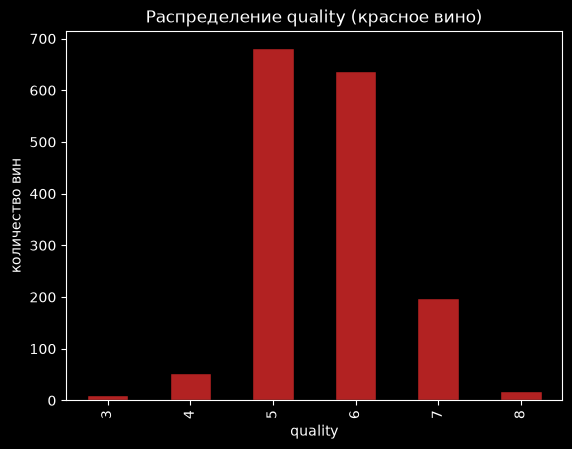

In [6]:
counts = df["quality"].value_counts().sort_index()
print(counts)
print("\nДоля оценок 5 и 6:", round(counts[[5, 6]].sum() / len(df), 3))

counts.plot(kind="bar", color="firebrick", edgecolor="black")
plt.title("Распределение quality (красное вино)")
plt.xlabel("quality")
plt.ylabel("количество вин")
plt.show()

**Выводы:**
- Хотя шкала 0–10, у красных вин встречаются только оценки **3…8**, и **82.5% вин имеют оценку 5 или 6**. Очень плохих (3 — всего 10 вин) и отличных (8 — 18 вин) единицы, девяток нет вовсе.
- Это сильный **дисбаланс**. Модель, минимизирующая среднеквадратичную ошибку, будет «тянуть» предсказания к центру (5–6), потому что там почти все данные. На редких крайних значениях ошибки будут заметно больше — это проверим в анализе ошибок.
- Поэтому при разбиении на train/test сохраняем пропорции оценок (**стратификация**), иначе редкие оценки могут не попасть в одну из частей.
- Задачу можно было бы решать как классификацию (оценки целые), но порядок оценок важен: ошибка 5→8 хуже, чем 5→6. Регрессия этот порядок учитывает.

### 2.4 Корреляции признаков с quality

Корреляция Пирсона показывает силу **линейной** связи (от −1 до +1).

volatile acidity       -0.391
total sulfur dioxide   -0.185
density                -0.175
chlorides              -0.129
pH                     -0.058
free sulfur dioxide    -0.051
residual sugar          0.014
fixed acidity           0.124
citric acid             0.226
sulphates               0.251
alcohol                 0.476
Name: quality, dtype: float64


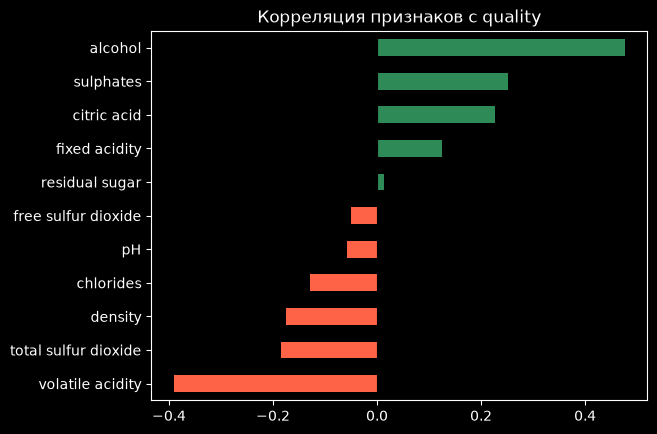

In [7]:
corr_with_target = df.corr()["quality"].drop("quality").sort_values()
print(corr_with_target.round(3))

colors = ["tomato" if v < 0 else "seagreen" for v in corr_with_target]
corr_with_target.plot(kind="barh", color=colors)
plt.title("Корреляция признаков с quality")
plt.axvline(0, color="black", lw=0.8)
plt.show()

**Выводы:**
- **`alcohol` (≈ +0.48)** — самая сильная связь: чем крепче вино, тем в среднем выше оценка. Более спелый виноград → больше сахара → больше спирта после брожения; такие вина обычно «полнотелее». Этот признак точно важен.
- **`volatile acidity` (≈ −0.39)** — летучая (уксусная) кислотность даёт неприятный уксусный привкус, эксперты снижают оценку. У красных вин это второй по силе признак.
- **`sulphates` (≈ +0.25)** и **`citric acid` (≈ +0.23)** — положительная связь: сульфаты защищают вино от окисления и бактерий, лимонная кислота добавляет «свежести».
- `total sulfur dioxide` (≈ −0.19), `density` (≈ −0.18), `chlorides` (≈ −0.13) — слабая отрицательная связь.
- `residual sugar`, `free sulfur dioxide`, `pH` почти не коррелируют с quality. **Но это не значит, что они бесполезны**: корреляция ловит только линейную связь одного признака; нелинейные зависимости и взаимодействия могут найти деревья.
- Даже самая сильная корреляция умеренная (0.48) → идеального предсказания не будет ни у какой модели.
- Корреляция **не означает причинность**: добавив спирта в плохое вино, мы не сделаем его хорошим.

### 2.5 Корреляции между признаками (мультиколлинеарность)

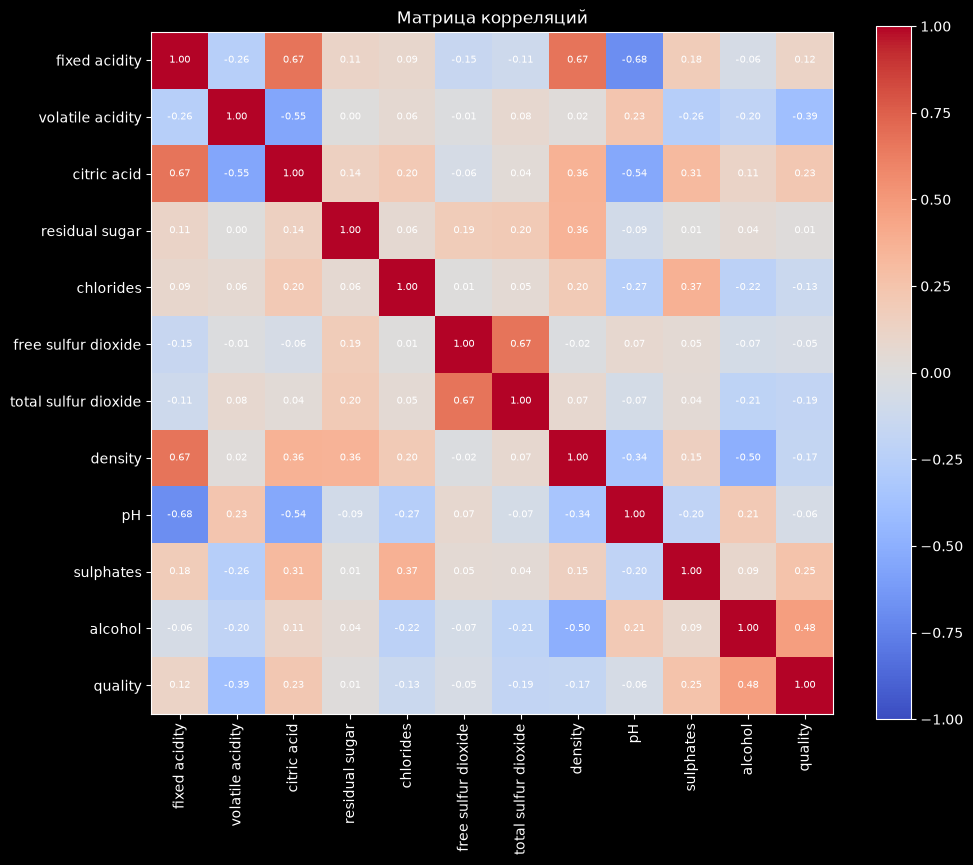

In [8]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im)
plt.title("Матрица корреляций")
plt.show()

**Выводы:**
- `fixed acidity` сильно связана с `pH` (≈ −0.68: больше кислот → ниже pH), с `citric acid` (≈ +0.67) и с `density` (≈ +0.67).
- `free sulfur dioxide` и `total sulfur dioxide` связаны (≈ +0.67): свободный SO₂ — часть общего.
- `alcohol` и `density` связаны (≈ −0.50): спирт легче воды. `citric acid` и `volatile acidity` — ≈ −0.55.
- **Значение для моделирования:** при мультиколлинеарности коэффициенты линейной регрессии становятся неустойчивыми — влияние может «делиться» между похожими признаками, поэтому интерпретировать коэффициенты нужно осторожно. Для деревьев это почти не влияет на качество, но может «размазывать» feature importance между похожими признаками.

### 2.6 Зависимость quality от ключевых признаков

«Ящик с усами»: линия — медиана, ящик — средние 50% значений, усы — основной разброс.

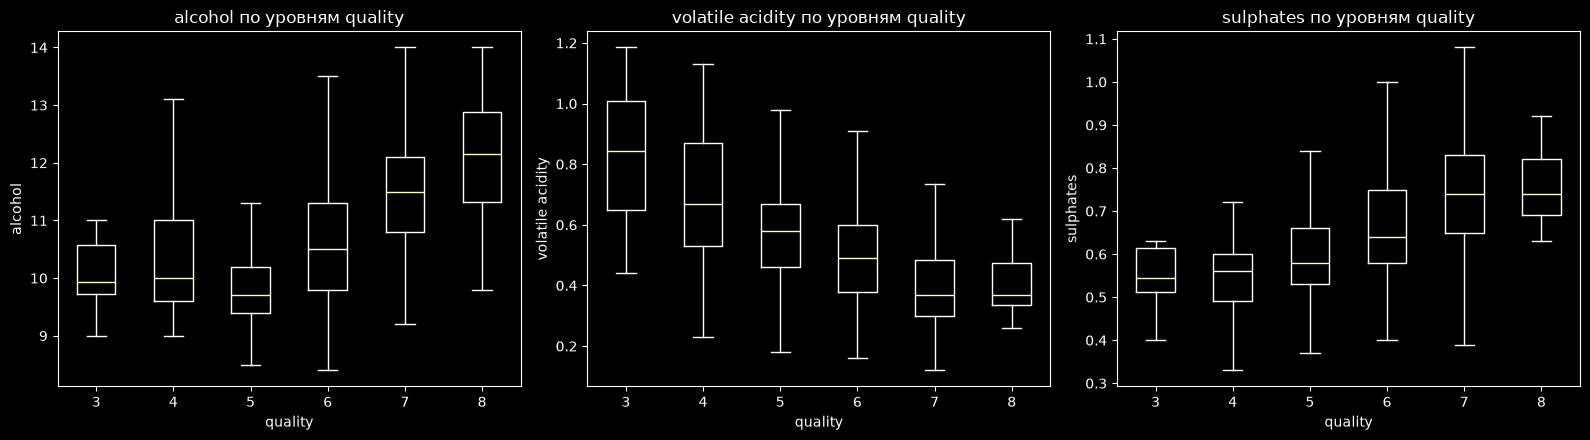

         alcohol  volatile acidity  sulphates
quality                                      
3          9.925             0.845      0.545
4         10.000             0.670      0.560
5          9.700             0.580      0.580
6         10.500             0.490      0.640
7         11.500             0.370      0.740
8         12.150             0.370      0.740


In [9]:
qualities = sorted(df["quality"].unique())
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, feat in zip(axes, ["alcohol", "volatile acidity", "sulphates"]):
    groups = [df.loc[df["quality"] == q, feat] for q in qualities]
    ax.boxplot(groups, showfliers=False)
    ax.set_xticks(range(1, len(qualities) + 1), qualities)
    ax.set_title(f"{feat} по уровням quality")
    ax.set_xlabel("quality")
    ax.set_ylabel(feat)
plt.tight_layout()
plt.show()

print(df.groupby("quality")[["alcohol", "volatile acidity", "sulphates"]].median())

**Выводы:**
- Медиана `alcohol` растёт от 5 к 8 (9.7 → 12.2%), но от 3 к 5 почти не меняется и даже чуть падает (9.9 → 9.7): связь **нелинейная**, с «изломом» около 5. Прямая линия такую форму не опишет; деревья (или полиномиальные признаки) — смогут.
- `volatile acidity` монотонно снижается с ростом оценки (0.85 у оценки 3 → 0.37 у 7–8): уксусный привкус — признак плохого вина.
- `sulphates` растёт с оценкой (0.55 → 0.74) и выходит на плато у 7–8.
- Ящики разных оценок сильно перекрываются: одинаковые значения признака бывают у вин с разными оценками. Плюс оценка субъективна (медиана оценок нескольких экспертов). Значит, в данных есть **неустранимый шум**.

### 2.7 Асимметрия распределений признаков

Асимметрия (skewness) > 1 означает сильный правый «хвост»: большинство значений маленькие, но есть редкие очень большие. Это важно для линейной регрессии — такие хвосты мешают описать связь прямой линией (см. статью про преобразования признаков).

Асимметрия (skewness) признаков:
chlorides               5.68
residual sugar          4.54
sulphates               2.43
total sulfur dioxide    1.52
free sulfur dioxide     1.25
fixed acidity           0.98
alcohol                 0.86
volatile acidity        0.67
citric acid             0.32
pH                      0.19
density                 0.07
dtype: float64


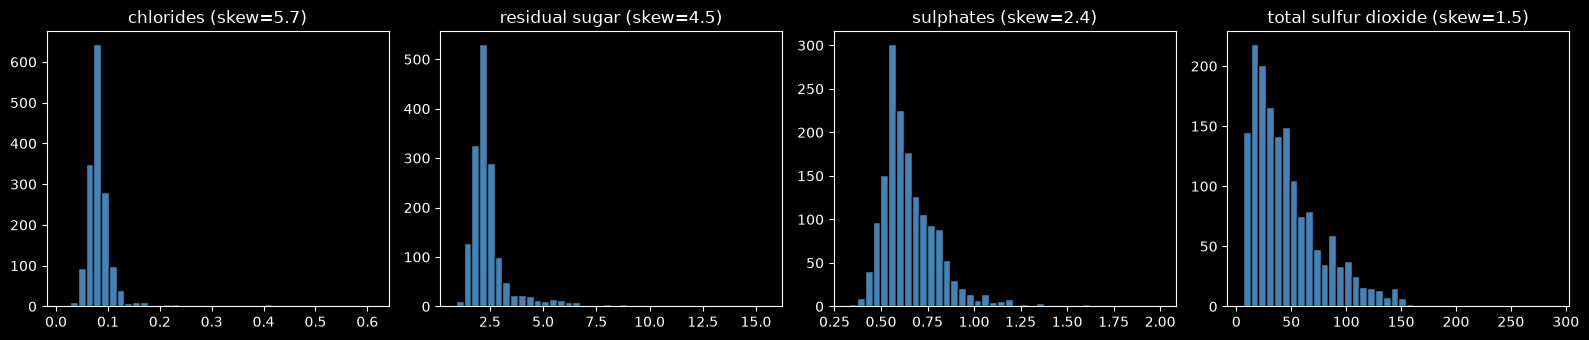

In [10]:
skew = df.drop(columns="quality").skew().sort_values(ascending=False)
print("Асимметрия (skewness) признаков:")
print(skew.round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, feat in zip(axes, ["chlorides", "residual sugar", "sulphates", "total sulfur dioxide"]):
    ax.hist(df[feat], bins=40, color="steelblue", edgecolor="black")
    ax.set_title(f"{feat} (skew={skew[feat]:.1f})")
plt.tight_layout()
plt.show()

**Выводы:**
- Сильно скошены вправо `chlorides` (5.7), `residual sugar` (4.5), `sulphates` (2.4), `total sulfur dioxide` (1.5), `free sulfur dioxide` (1.3). Почти симметричны `density`, `pH`, `citric acid`.
- Для таких признаков полезны **нелинейные преобразования** — логарифм, Box-Cox, Yeo-Johnson: они «сжимают» длинный хвост, распределение становится ближе к нормальному, а связь с целевой переменной — ближе к линейной. Попробуем это в разделе 5.2.
- Box-Cox работает только с положительными значениями, а у `citric acid` есть нули, поэтому используем **Yeo-Johnson** (работает с любыми значениями) и `log(1+x)`.

## 3. Разбиение на обучающую и тестовую выборки

- **Размер:** 80% train / 20% test (1279 / 320 вин). Данных немного, поэтому большую часть отдаём на обучение; 320 объектов в тесте достаточно для оценки.
- **Способ:** случайное разбиение со **стратификацией по quality** (`stratify=y`): доли каждой оценки в train и test одинаковые. Это важно из-за сильного дисбаланса — иначе редкие оценки (3, 8) могли бы целиком попасть в одну часть.
- `random_state=42` — разбиение одинаковое при каждом запуске (воспроизводимость).
- `quality` удаляется из признаков X — иначе модель «увидела бы ответ».

**Тестовая выборка используется только один раз — для финальной оценки.** Все решения (выбор вариантов модели, гиперпараметров, преобразований) принимаются по **5-фолдовой кросс-валидации на train**.

**Почему нельзя многократно оценивать модели на одном тесте:** если перебирать варианты и каждый раз смотреть на тест, мы фактически подбираем модель под эти конкретные 320 вин. Результат на тесте становится оптимистично завышенным, а на новых данных (скрытой выборке) модель покажет себя хуже — это переобучение на тестовую выборку.

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

# проверяем, что доли каждой оценки в train и test одинаковые
pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(3)

Train: (1279, 11)  Test: (320, 11)


,train,test
quality,,
3,0.006,0.006
4,0.033,0.034
5,0.426,0.425
6,0.399,0.400
7,0.124,0.125
8,0.012,0.009


Вспомогательные функции: метрики и кросс-валидация **только на train**.

Кросс-валидация: train делится на 5 частей; модель 5 раз обучается на 4 частях и проверяется на оставшейся; результаты усредняются.

In [12]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def evaluate(y_true, y_pred):
    return {"RMSE": float(rmse(y_true, y_pred)), "MAE": float(mean_absolute_error(y_true, y_pred))}

def cv_rmse(model):
    """Средний RMSE на 5-фолдовой кросс-валидации ТОЛЬКО по train."""
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    return -scores.mean()

def show(name):
    print(name, "на тесте:", {k: round(v, 4) for k, v in results[name].items()})

results = {}   # метрики всех моделей на ОДНОМ и том же тесте

## 4. Метрики и Baseline

**MAE** (Mean Absolute Error) $= \frac{1}{n}\sum |y_i - \hat y_i|$ — средняя абсолютная ошибка: на сколько баллов модель ошибается в среднем. Все ошибки весят пропорционально своей величине.

**RMSE** (Root Mean Squared Error) $= \sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ — корень из средней квадратичной ошибки, тоже в баллах quality, но ошибки сначала возводятся в квадрат.

**Почему RMSE сильнее реагирует на большие ошибки:** из-за квадрата. Ошибка 0.5 даёт вклад 0.25, а ошибка 2 — вклад 4: в 4 раза большая ошибка весит в 16 раз больше.

**Почему MAE и RMSE одной модели могут заметно различаться:** всегда RMSE ≥ MAE. Если все ошибки примерно одинаковые — RMSE ≈ MAE. Если большинство ошибок маленькие, но есть редкие большие промахи — RMSE заметно больше MAE.

### Baseline
Предсказываем **одну константу для всех вин**. Для RMSE оптимальная константа — **среднее** значение y: сумма $\sum (y_i - c)^2$ минимальна при $c = \bar y$ (производная $-2\sum(y_i - c) = 0$). Для MAE оптимальной была бы медиана. Среднее считаем **только по train** — иначе информация из теста попала бы в решение.

In [13]:
const = y_train.mean()
print("Константа (среднее quality на train):", round(const, 4))

y_pred_base = np.full(len(y_test), const)
results["Baseline (mean)"] = evaluate(y_test, y_pred_base)
show("Baseline (mean)")

Константа (среднее quality на train): 5.6372
Baseline (mean) на тесте: {'RMSE': 0.8033, 'MAE': 0.6812}


**Вывод:** константа даёт RMSE ≈ 0.80 — это «ничего не знающая» модель. Любая обученная модель должна быть заметно лучше, иначе она не извлекает из признаков полезной информации.

## 5. Линейная регрессия

### 5.1 Обычная линейная регрессия

Модель: $\hat y = w_0 + w_1 x_1 + \dots + w_d x_d$, веса подбираются минимизацией MSE на train.

**Нужно ли масштабирование?** На *качество* обычной линейной регрессии масштабирование не влияет. Но оно критично для **интерпретации коэффициентов**: без него коэффициент — это изменение quality при изменении признака на 1 единицу, а «1 единица» у `density` и у `total sulfur dioxide` — несравнимые вещи. После `StandardScaler` коэффициент означает изменение quality при изменении признака на одно стандартное отклонение, и коэффициенты можно сравнивать.

`StandardScaler` встроен в `Pipeline`, поэтому среднее и std считаются **только по train** (и внутри каждого фолда CV — только по обучающей части). Так нет утечки информации из теста.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(StandardScaler(), LinearRegression())

print("CV RMSE (train, 5 фолдов):", round(cv_rmse(lin_reg), 4))

lin_reg.fit(X_train, y_train)
y_pred_lr = lin_reg.predict(X_test)
results["Linear Regression"] = evaluate(y_test, y_pred_lr)

print("Train RMSE:", round(rmse(y_train, lin_reg.predict(X_train)), 4))
show("Linear Regression")

CV RMSE (train, 5 фолдов): 0.657
Train RMSE: 0.6486
Linear Regression на тесте: {'RMSE': 0.6375, 'MAE': 0.4951}


fixed acidity          -0.002
residual sugar          0.003
density                -0.004
citric acid            -0.027
free sulfur dioxide     0.066
chlorides              -0.083
pH                     -0.092
total sulfur dioxide   -0.128
sulphates               0.137
volatile acidity       -0.190
alcohol                 0.317
dtype: float64


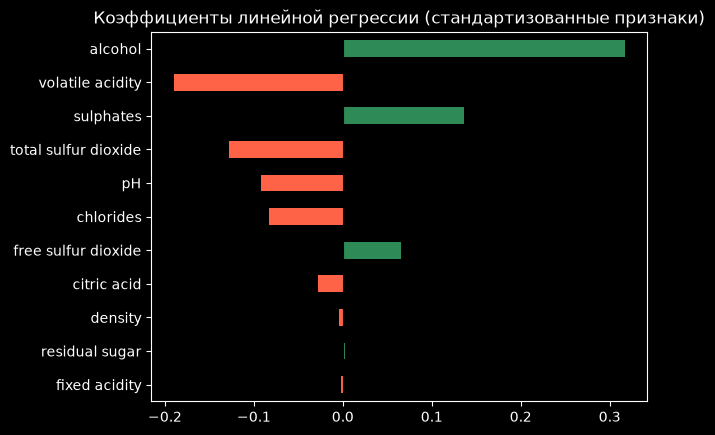

In [15]:
coefs = pd.Series(lin_reg.named_steps["linearregression"].coef_, index=X.columns)
coefs = coefs.reindex(coefs.abs().sort_values().index)
print(coefs.round(3))

colors = ["tomato" if v < 0 else "seagreen" for v in coefs]
coefs.plot(kind="barh", color=colors)
plt.title("Коэффициенты линейной регрессии (стандартизованные признаки)")
plt.axvline(0, color="black", lw=0.8)
plt.show()

**Анализ линейной регрессии:**
- RMSE ≈ 0.64 — заметно лучше baseline (0.80) и **ниже порога 0.70**. Линейная модель извлекает из признаков полезную информацию.
- Train RMSE (0.65), CV RMSE (0.66) и Test RMSE (0.64) почти одинаковы — модель **не переобучена**. Скорее она немного **недообучена**: прямая слишком проста для нелинейных зависимостей (излом по `alcohol`).
- Наибольшие по модулю коэффициенты: `alcohol` (+0.32), `volatile acidity` (−0.19), `sulphates` (+0.14), `total sulfur dioxide` (−0.13). Это **совпадает с EDA**: те же признаки имели наибольшую корреляцию с quality.
- Коэффициенты `density`, `fixed acidity`, `residual sugar` близки к нулю, хотя `density` коррелирует с quality (−0.18). Причина — **мультиколлинеарность**: информация о плотности уже есть в `alcohol` и `fixed acidity`, и модели не нужно использовать её отдельно. Поэтому коэффициенты нельзя напрямую читать как «важность» признака.

### 5.2 Улучшение линейной регрессии: преобразования признаков и полиномиальные признаки

Идеи из статьи про нелинейные преобразования ([dmitrymakarov.ru/data/transform-02](https://www.dmitrymakarov.ru/data/transform-02/)):
- **`log(1+x)`** для сильно скошенных признаков: сжимает длинный правый хвост;
- **Yeo-Johnson** (`PowerTransformer`): сам подбирает для каждого признака степень преобразования, чтобы распределение стало ближе к нормальному (в отличие от Box-Cox, работает с нулями). По умолчанию он ещё и стандартизирует признаки;
- **полиномиальные признаки 2-й степени** (`PolynomialFeatures`): добавляем квадраты и попарные произведения признаков (например, `alcohol²`, `alcohol × sulphates`). Так линейная модель может описывать **кривые** зависимости и взаимодействия. Признаков становится много (11 → 77), поэтому добавляем **регуляризацию Ridge** — штраф за большие веса, который защищает от переобучения. Силу штрафа `alpha` выбираем по CV.

**Важно:** в статье преобразования обучаются на всём датасете; мы же встраиваем их в `Pipeline`, поэтому параметры преобразований подбираются **только на train** — без утечки информации из теста. Вариант выбираем **по CV на train**, а не по тесту.

In [16]:
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge

# признаки с сильной правой асимметрией (см. раздел EDA про skewness)
skewed = ["chlorides", "residual sugar", "sulphates", "total sulfur dioxide", "free sulfur dioxide"]

log_transform = ColumnTransformer(
    [("log", FunctionTransformer(np.log1p), skewed)],   # log(1 + x): работает и для нулей
    remainder="passthrough",
)

lr_candidates = {
    "1) без преобразований": make_pipeline(StandardScaler(), LinearRegression()),
    "2) log(1+x) скошенных признаков": make_pipeline(log_transform, StandardScaler(), LinearRegression()),
    "3) Yeo-Johnson (PowerTransformer)": make_pipeline(PowerTransformer(), LinearRegression()),
}
for alpha in [10, 50, 200, 500]:
    lr_candidates[f"4) Yeo-Johnson + полином. признаки 2 ст. + Ridge(alpha={alpha})"] = make_pipeline(
        PowerTransformer(), PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(), Ridge(alpha=alpha))

lr_cv = {}
for name, m in lr_candidates.items():
    lr_cv[name] = cv_rmse(m)
    train_score = rmse(y_train, m.fit(X_train, y_train).predict(X_train))
    print(f"{name:62s} CV RMSE = {lr_cv[name]:.4f}   (train RMSE = {train_score:.4f})")

1) без преобразований                                          CV RMSE = 0.6570   (train RMSE = 0.6486)
2) log(1+x) скошенных признаков                                CV RMSE = 0.6547   (train RMSE = 0.6469)
3) Yeo-Johnson (PowerTransformer)                              CV RMSE = 0.6490   (train RMSE = 0.6424)
4) Yeo-Johnson + полином. признаки 2 ст. + Ridge(alpha=10)     CV RMSE = 0.6566   (train RMSE = 0.5993)
4) Yeo-Johnson + полином. признаки 2 ст. + Ridge(alpha=50)     CV RMSE = 0.6514   (train RMSE = 0.6018)
4) Yeo-Johnson + полином. признаки 2 ст. + Ridge(alpha=200)    CV RMSE = 0.6467   (train RMSE = 0.6092)
4) Yeo-Johnson + полином. признаки 2 ст. + Ridge(alpha=500)    CV RMSE = 0.6506   (train RMSE = 0.6213)


In [17]:
best_lr_name = min(lr_cv, key=lr_cv.get)
print("Выбран вариант (по CV на train):", best_lr_name)

lin_reg_best = lr_candidates[best_lr_name]
lin_reg_best.fit(X_train, y_train)
y_pred_lr_best = lin_reg_best.predict(X_test)
results["Linear Regression (преобразования)"] = evaluate(y_test, y_pred_lr_best)

print("Train RMSE:", round(rmse(y_train, lin_reg_best.predict(X_train)), 4))
show("Linear Regression (преобразования)")

Выбран вариант (по CV на train): 4) Yeo-Johnson + полином. признаки 2 ст. + Ridge(alpha=200)
Train RMSE: 0.6092
Linear Regression (преобразования) на тесте: {'RMSE': 0.6246, 'MAE': 0.4916}


**Выводы:**
- `log(1+x)` и Yeo-Johnson немного улучшают CV RMSE (0.657 → 0.655 → 0.649): «выпрямление» скошенных признаков помогает прямой лучше описать связь.
- Полиномиальные признаки + Ridge дают лучший CV RMSE (≈0.647 при `alpha=200`); на тесте — RMSE ≈ 0.625 против 0.638 у обычной линейной регрессии.
- При маленькой регуляризации (`alpha=10`) полиномиальная модель хуже по CV, хотя на train у неё ошибка меньше всех (≈0.60 против ≈0.66 по CV): признаков много, и она начинает подстраиваться под шум. Это наглядный пример **переобучения** и того, как регуляризация с ним борется. При слишком сильной (`alpha=500`) — снова хуже: штраф мешает модели выучить даже полезные зависимости.
- Выигрыш небольшой: основные нелинейности в данных линейная модель даже с преобразованиями ловит лишь частично. Деревья справятся лучше.

## 6. Random Forest Regressor

Случайный лес — среднее предсказаний многих решающих деревьев. Каждое дерево учится на бутстрэп-подвыборке объектов (случайная выборка с повторениями) и в каждом разбиении рассматривает случайное подмножество признаков. Отдельное глубокое дерево сильно переобучается, но усреднение многих *разных* деревьев сильно уменьшает разброс ошибок. Деревья естественно ловят нелинейности и взаимодействия признаков, масштабирование им не нужно.

500 деревьев: больше деревьев — стабильнее результат (переобучения от числа деревьев в лесу нет, только дольше считается).

In [18]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)

print("CV RMSE (train, 5 фолдов):", round(cv_rmse(rf), 4))

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
results["Random Forest"] = evaluate(y_test, y_pred_rf)

print("Train RMSE:", round(rmse(y_train, rf.predict(X_train)), 4))
show("Random Forest")

CV RMSE (train, 5 фолдов): 0.5981
Train RMSE: 0.2145
Random Forest на тесте: {'RMSE': 0.567, 'MAE': 0.4196}


citric acid             0.045
free sulfur dioxide     0.047
fixed acidity           0.052
residual sugar          0.055
density                 0.055
pH                      0.060
chlorides               0.062
total sulfur dioxide    0.081
volatile acidity        0.124
sulphates               0.138
alcohol                 0.282
dtype: float64


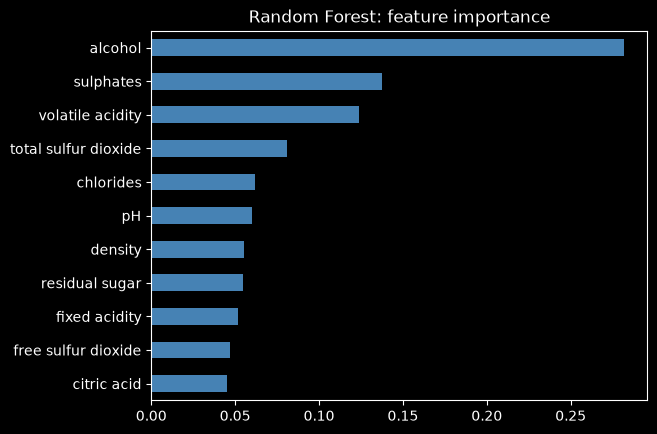

In [19]:
rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
print(rf_imp.round(3))
rf_imp.plot(kind="barh", color="steelblue")
plt.title("Random Forest: feature importance")
plt.show()

**Анализ Random Forest:**
- RMSE ≈ 0.567 — значительно лучше линейной регрессии и baseline, порог пройден с запасом.
- Train RMSE ≈ 0.21 намного ниже тестового: лес почти «запоминает» обучающие объекты (глубокие деревья). Это нормально для леса, а честная оценка — CV (0.60) и test (0.57), они согласуются.
- Отчасти высокое качество леса связано с **дубликатами**: одинаковые вина в train и test лес предсказывает почти точно.
- **Важность признаков:** `alcohol` (0.28) на первом месте, затем `sulphates` (0.14) и `volatile acidity` (0.12) — **ровно те же признаки**, что выделили EDA и линейная регрессия. Дальше важности примерно равны (0.05–0.08).
- Интересно, что у леса `sulphates` важнее `volatile acidity`, хотя по корреляции наоборот: связь sulphates с quality **нелинейная** (рост и плато), и деревья используют её лучше, чем линейная корреляция показывает.

## 7. Gradient Boosting Regressor

Градиентный бустинг строит деревья **последовательно**: каждое новое (неглубокое) дерево учится исправлять ошибки уже построенного ансамбля; вклад каждого дерева умножается на `learning_rate`. Лес уменьшает разброс усреднением независимых деревьев, а бустинг шаг за шагом уменьшает **смещение**, приближаясь к сложной зависимости.

Гиперпараметры выбираем по **CV на train** (тест не трогаем): сравним настройки по умолчанию и две более мощные конфигурации (больше деревьев с меньшим шагом, глубже деревья, `subsample=0.8` — каждое дерево учится на 80% объектов, это регуляризация).

In [20]:
from sklearn.ensemble import GradientBoostingRegressor

gb_candidates = {
    "default (100 деревьев, depth=3, lr=0.1)": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "500 деревьев, depth=5, lr=0.05, subsample=0.8": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=5, subsample=0.8,
        min_samples_leaf=5, random_state=RANDOM_STATE),
    "1000 деревьев, depth=6, lr=0.03, subsample=0.8": GradientBoostingRegressor(
        n_estimators=1000, learning_rate=0.03, max_depth=6, subsample=0.8,
        min_samples_leaf=5, random_state=RANDOM_STATE),
}

gb_cv = {name: cv_rmse(m) for name, m in gb_candidates.items()}
for name, score in gb_cv.items():
    print(f"{name:50s} CV RMSE = {score:.4f}")

default (100 деревьев, depth=3, lr=0.1)            CV RMSE = 0.6332
500 деревьев, depth=5, lr=0.05, subsample=0.8      CV RMSE = 0.6215
1000 деревьев, depth=6, lr=0.03, subsample=0.8     CV RMSE = 0.6212


Дефолтный бустинг заметно хуже (100 неглубоких деревьев не успевают выучить зависимость — недообучение). Две мощные конфигурации почти равны; выбираем лучшую по CV.

In [21]:
best_gb_name = min(gb_cv, key=gb_cv.get)
print("Выбрана конфигурация:", best_gb_name)

gb = gb_candidates[best_gb_name]
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
results["Gradient Boosting"] = evaluate(y_test, y_pred_gb)

print("Train RMSE:", round(rmse(y_train, gb.predict(X_train)), 4))
show("Gradient Boosting")

Выбрана конфигурация: 1000 деревьев, depth=6, lr=0.03, subsample=0.8
Train RMSE: 0.0429
Gradient Boosting на тесте: {'RMSE': 0.575, 'MAE': 0.3935}


residual sugar          0.050
citric acid             0.052
free sulfur dioxide     0.053
fixed acidity           0.061
pH                      0.064
density                 0.066
chlorides               0.070
total sulfur dioxide    0.089
volatile acidity        0.121
sulphates               0.134
alcohol                 0.241
dtype: float64


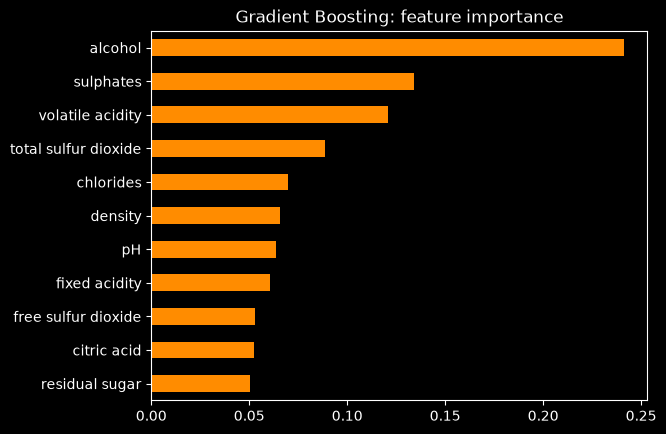

In [22]:
gb_imp = pd.Series(gb.feature_importances_, index=X.columns).sort_values()
print(gb_imp.round(3))
gb_imp.plot(kind="barh", color="darkorange")
plt.title("Gradient Boosting: feature importance")
plt.show()

**Анализ Gradient Boosting:**
- RMSE ≈ 0.575 — на уровне Random Forest, порог пройден. MAE у бустинга даже лучше (0.39 против 0.42): он точнее на «обычных» винах, но иногда сильнее ошибается на редких — отсюда чуть больший RMSE.
- Train RMSE ≈ 0.04 — бустинг почти идеально выучил train, но CV (0.62) и test (0.575) гораздо выше: модель очень гибкая и частично подстраивается под шум. Тем не менее на новых данных она работает хорошо — именно поэтому параметры выбирались по CV, а не по train.
- Важность признаков почти совпадает с лесом: `alcohol`, `sulphates`, `volatile acidity`, затем `total sulfur dioxide`. Небольшие отличия в хвосте (например, `density` чуть важнее у бустинга) — следствие коррелированных признаков: разные модели «выбирают» разные из похожих признаков.

## 8. Честное сравнение моделей

Все модели обучены на одном и том же train и оценены на одном и том же test (одно разбиение с `random_state=42`); все варианты и гиперпараметры выбирались по CV на train.

In [23]:
results_df = pd.DataFrame(results).T[["RMSE", "MAE"]].round(4)
results_df["RMSE < 0.70"] = results_df["RMSE"] < 0.70
results_df["лучше baseline"] = results_df["RMSE"] < results_df.loc["Baseline (mean)", "RMSE"]
results_df

,RMSE,MAE,RMSE < 0.70,лучше baseline
Baseline (mean),0.8033,0.6812,False,False
Linear Regression,0.6375,0.4951,True,True
Linear Regression (преобразования),0.6246,0.4916,True,True
Random Forest,0.5670,0.4196,True,True
Gradient Boosting,0.5750,0.3935,True,True


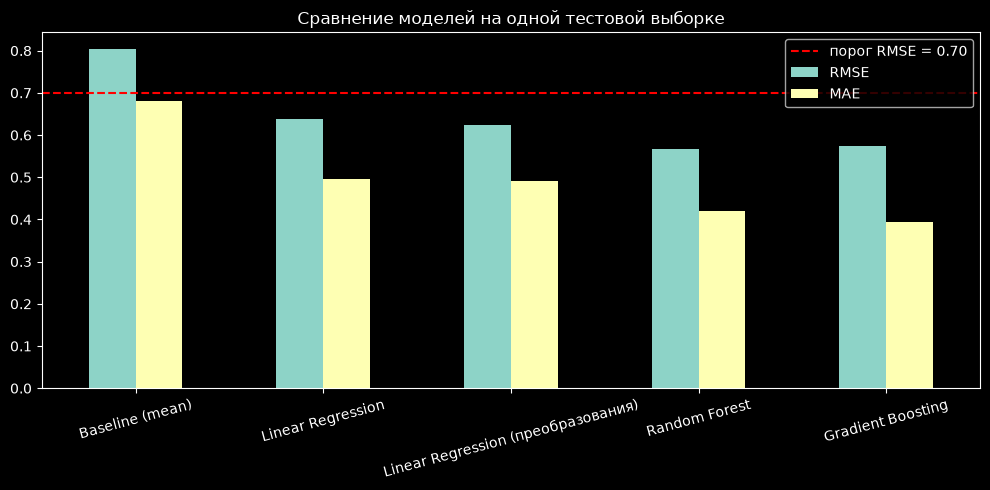

In [24]:
results_df[["RMSE", "MAE"]].plot(kind="bar", rot=15, figsize=(10, 5))
plt.axhline(0.70, color="red", ls="--", label="порог RMSE = 0.70")
plt.legend()
plt.title("Сравнение моделей на одной тестовой выборке")
plt.tight_layout()
plt.show()

**Выводы по сравнению:**
- **Baseline превзошли все модели**, и **все модели проходят порог RMSE < 0.70** → признаки действительно содержат информацию о качестве.
- **Линейная регрессия** (0.638) улучшает baseline на ~20%. Преобразования признаков и полиномиальные признаки дают небольшой прирост (0.625): часть нелинейности они ловят, но прямая/полином 2-й степени — всё ещё слишком жёсткая форма.
- **Random Forest (0.567) и Gradient Boosting (0.575)** — лучшие, разница между ними мала и в пределах случайности (CV 0.598 и 0.621). Деревья разбивают пространство признаков на области и могут описать любую форму зависимости (излом по спирту, плато по сульфатам) и взаимодействия.
- Лес хорош без настройки: глубокие деревья хорошо «запоминают» похожие/дублирующиеся объекты, а усреднение 500 деревьев не даёт этому превратиться в переобучение. Бустингу по умолчанию не хватило сложности — понадобилось больше деревьев и глубина.
- У всех моделей RMSE заметно больше MAE (≈0.57 vs ≈0.42 у леса): большинство ошибок маленькие, но на редких винах (3, 4, 8) есть крупные промахи, которые RMSE штрафует сильнее.

## 9. Feature importance — сравнение моделей

Feature importance у деревьев (impurity-based) — насколько в сумме уменьшилась ошибка (MSE) во всех разбиениях по этому признаку. Для линейной регрессии аналог — модули стандартизованных коэффициентов.

                      |corr| с quality  LinReg |coef| (норм.)  Random Forest  \
alcohol                          0.229                  0.302          0.282   
sulphates                        0.121                  0.130          0.138   
volatile acidity                 0.188                  0.181          0.124   
total sulfur dioxide             0.089                  0.122          0.081   
chlorides                        0.062                  0.079          0.062   
pH                               0.028                  0.087          0.060   
density                          0.084                  0.004          0.055   
residual sugar                   0.007                  0.003          0.055   
fixed acidity                    0.060                  0.002          0.052   
free sulfur dioxide              0.024                  0.063          0.047   
citric acid                      0.109                  0.026          0.045   

                      Gradient Boosting

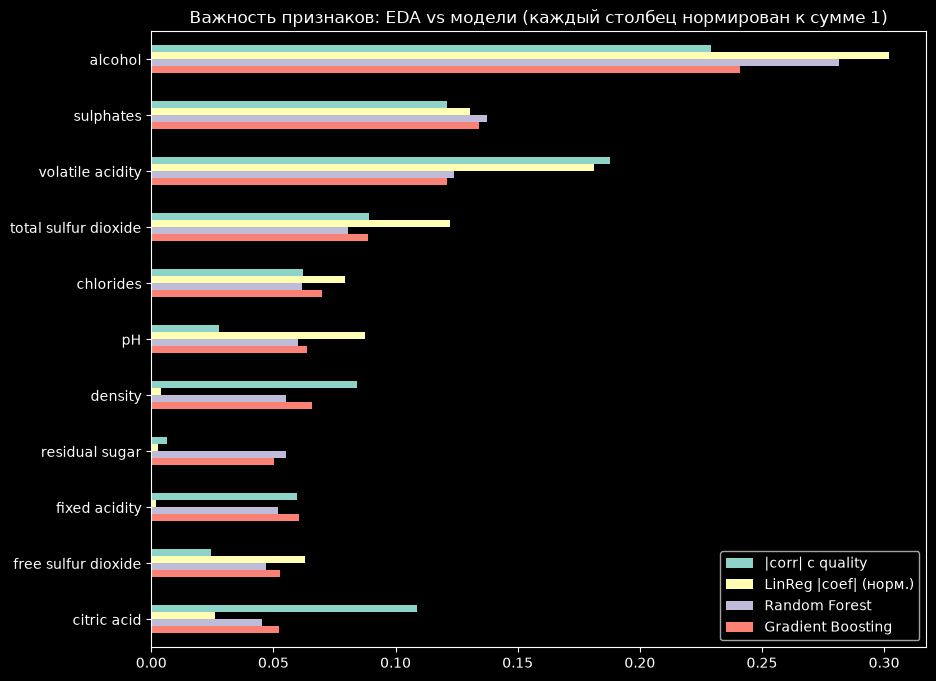

Топ-3 RF: ['alcohol', 'sulphates', 'volatile acidity']
Топ-3 GB: ['alcohol', 'sulphates', 'volatile acidity']


In [25]:
lr_abs = coefs.abs() / coefs.abs().sum()   # нормируем |коэф.|, чтобы сравнивать в одном масштабе
importance = pd.DataFrame({
    "|corr| с quality": corr_with_target.abs() / corr_with_target.abs().sum(),
    "LinReg |coef| (норм.)": lr_abs,
    "Random Forest": rf_imp,
    "Gradient Boosting": gb_imp,
}).sort_values("Random Forest", ascending=False)
print(importance.round(3))

importance.plot(kind="barh", figsize=(10, 8)).invert_yaxis()
plt.title("Важность признаков: EDA vs модели (каждый столбец нормирован к сумме 1)")
plt.show()

print("Топ-3 RF:", list(rf_imp.sort_values(ascending=False).index[:3]))
print("Топ-3 GB:", list(gb_imp.sort_values(ascending=False).index[:3]))

**Выводы:**
1. **`alcohol` — самый важный признак во всех подходах** (корреляция, линейная регрессия, лес, бустинг).
2. **`sulphates` и `volatile acidity`** — 2-е и 3-е места у всех моделей. Результаты EDA подтвердились.
3. **`citric acid`**: заметная корреляция (+0.23), но малая важность в моделях — её информация во многом дублируется `volatile acidity` и `fixed acidity` (корреляции −0.55 и +0.67).
4. **`density`**: в EDA корреляция −0.18, у линейной модели коэффициент ≈ 0, у деревьев средняя важность — классический пример того, как коррелированный признак (с `alcohol`, `fixed acidity`) «перехватывает» или «отдаёт» важность.
5. `residual sugar`, `pH`: почти нулевая корреляция, но ненулевая важность у деревьев — признак слабой **нелинейной** связи или взаимодействий.

**Можно ли по feature importance утверждать, что изменение признака — *причина* изменения качества?** **Нет.**
- Feature importance показывает, насколько признак *помогает модели предсказывать*, т.е. отражает **связь в данных**, а не причинно-следственную связь.
- Возможны скрытые общие причины: и высокая крепость, и высокая оценка могут быть следствием хорошего урожая/спелого винограда. Если добавить спирта в плохое вино, оно не станет лучше.
- При коррелированных признаках важность произвольно делится между ними (пример `density` / `alcohol`), так что даже величина важности неоднозначна.
- Impurity-based importance к тому же смещена в пользу признаков с большим числом уникальных значений.
- Для причинных выводов нужен контролируемый эксперимент (меняем один фактор при прочих равных), а не наблюдательные данные.

## 10. Анализ ошибок лучшей модели

Лучшая модель выбирается по RMSE из итоговой таблицы. Ошибка (остаток) = `y_true − y_pred`: положительная → модель **недооценила** вино.

Лучшая модель: Random Forest


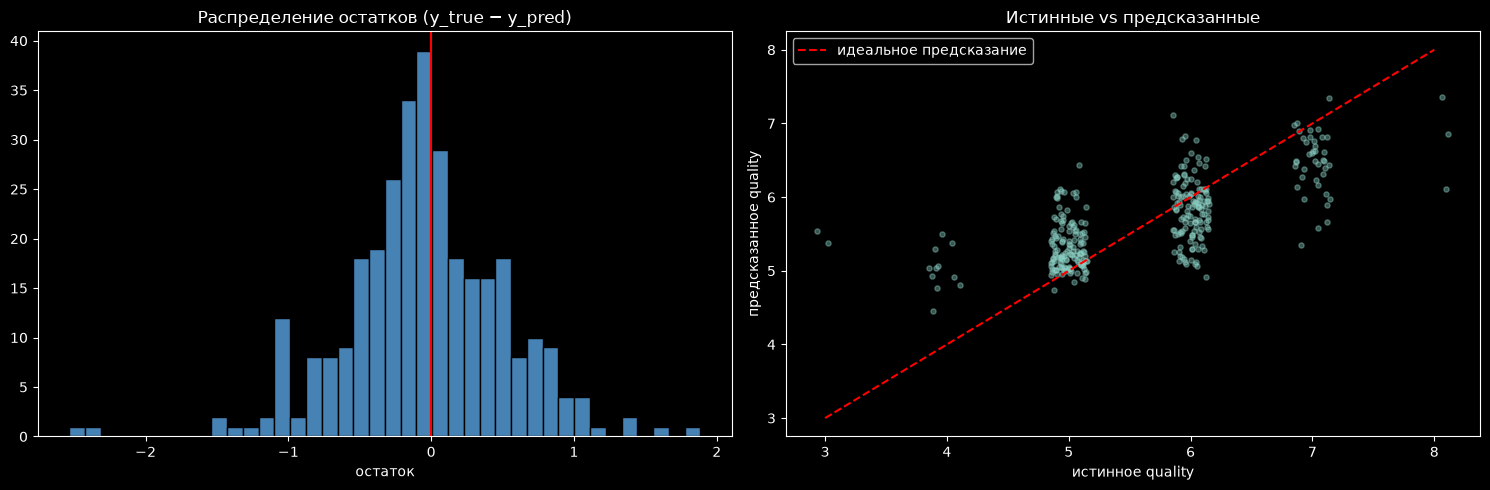

Доля объектов с |ошибкой| < 0.5: 0.656
Доля объектов с |ошибкой| > 1.0: 0.081


In [26]:
model_preds = {
    "Linear Regression": y_pred_lr,
    "Linear Regression (преобразования)": y_pred_lr_best,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
}
best_name = results_df.drop(index="Baseline (mean)")["RMSE"].idxmin()
best_pred = model_preds[best_name]
print("Лучшая модель:", best_name)

err = pd.DataFrame({"y_true": y_test.values, "y_pred": best_pred}, index=y_test.index)
err["residual"] = err["y_true"] - err["y_pred"]   # > 0 -> модель недооценила вино
err["abs_error"] = err["residual"].abs()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(err["residual"], bins=40, color="steelblue", edgecolor="black")
axes[0].axvline(0, color="red")
axes[0].set_title("Распределение остатков (y_true − y_pred)")
axes[0].set_xlabel("остаток")

jitter = np.random.uniform(-0.15, 0.15, len(err))   # небольшой сдвиг, чтобы точки не слипались
axes[1].scatter(err["y_true"] + jitter, err["y_pred"], alpha=0.4, s=14)
axes[1].plot([3, 8], [3, 8], "r--", label="идеальное предсказание")
axes[1].set_xlabel("истинное quality")
axes[1].set_ylabel("предсказанное quality")
axes[1].set_title("Истинные vs предсказанные")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Доля объектов с |ошибкой| < 0.5:", round((err["abs_error"] < 0.5).mean(), 3))
print("Доля объектов с |ошибкой| > 1.0:", round((err["abs_error"] > 1.0).mean(), 3))

**Выводы:**
- Остатки сосредоточены около нуля, распределение близко к симметричному, но с «хвостами» — редкие крупные ошибки.
- ~66% вин предсказаны с ошибкой меньше 0.5 балла, и только ~8% — с ошибкой больше 1 балла.
- На scatter-графике видно **«сжатие к центру»**: для вин с quality 3–4 предсказания завышены, для 7–8 — занижены; облако точек «лежит» более полого, чем красная диагональ.

          n  mean_pred  mean_residual    MAE   RMSE
y_true                                             
3         2      5.455         -2.455  2.455  2.456
4        11      5.015         -1.015  1.015  1.055
5       136      5.334         -0.334  0.347  0.466
6       128      5.829          0.171  0.354  0.449
7        40      6.467          0.533  0.551  0.672
8         3      6.778          1.222  1.222  1.325


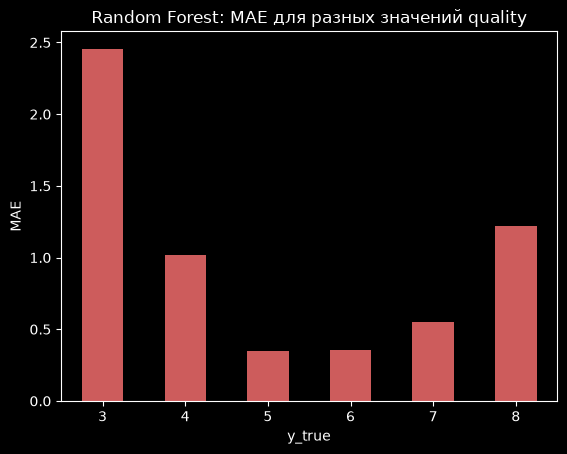

In [27]:
by_quality = err.groupby("y_true").agg(
    n=("y_true", "size"),
    mean_pred=("y_pred", "mean"),
    mean_residual=("residual", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("residual", lambda r: np.sqrt(np.mean(r ** 2))),
).round(3)
print(by_quality)

by_quality["MAE"].plot(kind="bar", color="indianred", rot=0)
plt.title(f"{best_name}: MAE для разных значений quality")
plt.ylabel("MAE")
plt.show()

**Модель работает очень неравномерно по оценкам:**
- На частых оценках **5 и 6** ошибка маленькая (MAE ≈ 0.35).
- На **3, 4 и 8** ошибка в разы больше (MAE от 1 до 2.5). Средний остаток отрицательный у низких оценок (модель завышает: вину на 3 ставит ≈5.5) и положительный у высоких (вину на 8 ставит ≈6.8).

**Почему модель хуже предсказывает редкие значения quality:**
1. **Мало примеров:** в train всего 8 вин с оценкой 3 и 15 — с оценкой 8. Модели не из чего выучить, чем они отличаются.
2. **Минимизация MSE** оптимизирует *среднюю* ошибку по всем объектам; выгоднее хорошо предсказывать массовые 5–6.
3. **Механика деревьев:** предсказание листа — среднее объектов в нём; редкое вино почти всегда попадает в лист вместе с «соседями» с оценками 5–6, и среднее тянется к центру. Лес дополнительно усредняет 500 деревьев — это ещё сильнее сглаживает крайние предсказания.

Объекты с наибольшими ошибками и «типичные» значения признаков (медианы по train) для каждой оценки:

In [28]:
worst = err.sort_values("abs_error", ascending=False).head(10)
worst.join(X_test)[["y_true", "y_pred", "residual", "alcohol", "volatile acidity",
                    "sulphates", "citric acid", "total sulfur dioxide"]].round(3)

,y_true,y_pred,residual,alcohol,volatile acidity,sulphates,citric acid,total sulfur dioxide
1374,3,5.534,-2.534,9.8,0.815,0.51,0.00,29.0
832,3,5.376,-2.376,9.9,0.440,0.86,0.42,48.0
440,8,6.114,1.886,9.8,0.310,0.82,0.72,29.0
943,7,5.350,1.650,9.7,0.500,0.60,0.34,45.0
703,4,5.502,-1.502,9.6,0.380,0.70,0.48,84.0
1322,5,6.430,-1.430,11.4,0.340,0.55,0.42,18.0
442,7,5.586,1.414,11.2,0.685,0.68,0.76,43.0
1233,4,5.380,-1.380,9.3,0.230,0.49,0.37,36.0
230,7,5.664,1.336,12.2,0.480,0.62,0.04,106.0
1482,4,5.296,-1.296,10.3,0.580,0.57,0.54,9.0


In [29]:
# «типичные» значения признаков для каждой оценки (медианы по train)
pd.concat([X_train, y_train], axis=1).groupby("quality")[
    ["alcohol", "volatile acidity", "sulphates", "citric acid", "total sulfur dioxide"]
].median().round(3)

,alcohol,volatile acidity,sulphates,citric acid,total sulfur dioxide
quality,,,,,
3,10.075,0.928,0.545,0.035,14.0
4,10.050,0.653,0.560,0.085,29.0
5,9.600,0.580,0.580,0.230,50.0
6,10.575,0.500,0.640,0.270,36.0
7,11.400,0.360,0.740,0.400,26.0
8,12.500,0.400,0.740,0.340,24.0


**Разбор объектов с наибольшими ошибками** (сравниваем две таблицы выше; при `random_state=42` строки те же):
- **Почти все крупные ошибки — вина с редкими оценками** (3, 4, 7, 8) или вина, нетипичные для своей оценки.
- **Строка 1374** (оценка 3, предсказано ≈5.5): очень высокая `volatile acidity` (0.815) и нулевая `citric acid` — типичные признаки плохого вина. Модель «увидела» это и снизила предсказание, но не до 3: вин с оценкой 3 в train всего 8, и в листьях деревьев они усредняются вместе с пятёрками.
- **Строка 832** (оценка 3, предсказано ≈5.4): химия вполне нормальная (`volatile acidity` 0.44, `sulphates` 0.86 — как у хороших вин). Дефект этого вина, видимо, в том, чего нет в данных (аромат, вкус, порча), или это шум экспертной оценки.
- **Строка 440** (оценка 8, предсказано ≈6.1): `alcohol` всего 9.8% — типично для оценки 5, а не 8 (медиана 12.5). По главному признаку вино выглядит средним, хотя `sulphates` и `citric acid` высокие. Модель доверилась спирту.
- **Строка 943** (оценка 7, предсказано ≈5.4): крепость 9.7% и средняя кислотность — по химии неотличимо от пятёрок.
- **Строка 1322** (оценка 5, предсказано ≈6.4): `alcohol` 11.4% — как у семёрок, поэтому модель переоценила вино.

**Итог:** модель опирается в основном на `alcohol`, `sulphates` и `volatile acidity`; вина, у которых эти признаки «не соответствуют» оценке, она предсказывает плохо. Хорошее среднее RMSE достигается в основном за счёт массовых вин 5–6. Улучшить можно, добавив признаки (сорт, год, регион), веса для редких оценок или более мощные модели (например, CatBoost).

## 11. Итоговые выводы

1. **Данные:** 1599 красных вин, 11 числовых признаков, без пропусков, ~15% дубликатов, сильный дисбаланс quality (82.5% — оценки 5–6), у ряда признаков сильная асимметрия.
2. **Разбиение:** 80/20 со стратификацией по quality, `random_state=42`; все решения — по 5-fold CV на train, тест использован один раз.
3. **Baseline** (среднее train): RMSE ≈ 0.80. Все модели его превзошли.
4. **Линейная регрессия:** RMSE ≈ 0.64 — порог пройден. Преобразования признаков (log, Yeo-Johnson) и полиномиальные признаки с Ridge дали небольшое улучшение (≈0.625).
5. **Random Forest (≈0.567) и Gradient Boosting (≈0.575)** — лучшие модели: деревья учитывают нелинейности и взаимодействия.
6. **Самые важные признаки** во всех моделях — `alcohol`, `sulphates`, `volatile acidity`; это совпадает с EDA. Feature importance — не доказательство причинности.
7. **Ошибки:** модель хорошо предсказывает массовые оценки 5–6 и плохо — редкие 3, 4, 8 (сжатие к среднему из-за малого числа примеров и минимизации MSE).